# Phase 3: Advanced Object Tracking Mastery
Welcome to Phase 3 of the Team Chati Pati Computer Vision Bootcamp.
Detecting objects frame-by-frame is not enough for real-world video analytics. We need to assign a unique ID to each object and track its trajectory over time, even when the detector fails or objects overlap.

**Roadmap Overview:**
* **Day 16 & 17:** Centroid & IoU Tracking (The greedy approach and its flaws).
* **Day 18:** The Assignment Problem (Hungarian Algorithm).
* **Day 19:** Predicting the Future (Kalman Filter).
* **Day 20:** Object-Oriented Track Lifecycle (Birth, Memory, Death).
* **Day 21:** End-to-End Pipeline (YOLOv8 + Custom SORT Tracker).
* **Day 22 & 23:** Tracking Comparison (SORT vs. ByteTrack) & Failure Analysis.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.spatial import distance
from scipy.optimize import linear_sum_assignment
from filterpy.kalman import KalmanFilter
from ultralytics import YOLO

plt.rcParams['figure.figsize'] = (10, 6)

def show_frames(frames, titles, cols=3):
    rows = (len(frames) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    for i, ax in enumerate(axes.flatten()):
        if i < len(frames):
            ax.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
            ax.set_title(titles[i])
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Helper from Phase 2
def calculate_iou(boxA, boxB):
    xA, yA = max(boxA[0], boxB[0]), max(boxA[1], boxB[1])
    xB, yB = min(boxA[2], boxB[2]), min(boxA[3], boxB[3])
    interArea = max(0, xB - xA) * max(0, yB - yA)
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])
    union = boxAArea + boxBArea - interArea
    return interArea / float(union) if union > 0 else 0.0

## Day 16 & 17 — Centroid & IoU Tracking
**Topics:** Distance Matching, IoU Matrix, Greedy Matching, ID Switches

### 1. Centroid Distance Tracking
The simplest way to track is to calculate the center point (centroid) of bounding boxes in Frame $T$ and Frame $T+1$. We assign the ID of the closest past centroid to the new centroid using Euclidean Distance.
* **Flaw:** If a fast-moving object passes a slow-moving one, their distances might get mixed up.

### 2. IoU Tracking & Greedy Matching
Instead of centroids, we use the Intersection over Union (IoU) of boxes. 
* **The Matrix:** We build a cost matrix comparing every Detection to every existing Track.
* **Greedy Approach:** Pick the highest IoU, assign it, move to the next. 
* **The ID Switch Problem:** Greedy matching fails during occlusions. If Object A crosses Object B, greedy matching will steal the ID of whichever object randomly gets evaluated first, leading to an **ID Switch**.

In [2]:
# Synthetic Data: Generating two overlapping tracks
# Detections: [x1, y1, x2, y2]
frame1_tracks = [[10, 10, 50, 50], [100, 100, 140, 140]] # IDs: 0, 1
frame2_detections = [[110, 110, 150, 150], [20, 20, 60, 60]] # Shuffled order!

def compute_iou_matrix(tracks, detections):
    matrix = np.zeros((len(tracks), len(detections)))
    for t, trk in enumerate(tracks):
        for d, det in enumerate(detections):
            matrix[t, d] = calculate_iou(trk, det)
    return matrix

iou_matrix = compute_iou_matrix(frame1_tracks, frame2_detections)
print("IoU Matrix (Tracks vs Detections):\n", np.round(iou_matrix, 2))

# Greedy Matching
print("\n--- GREEDY MATCHING ---")
matched_tracks = set()
matched_dets = set()

for t in range(len(frame1_tracks)):
    best_iou = 0
    best_d = -1
    for d in range(len(frame2_detections)):
        if d not in matched_dets and iou_matrix[t, d] > best_iou:
            best_iou = iou_matrix[t, d]
            best_d = d
            
    if best_iou > 0.3: # Threshold
        print(f"Track {t} uniquely matched to Detection {best_d} (IoU: {best_iou:.2f})")
        matched_tracks.add(t)
        matched_dets.add(best_d)

IoU Matrix (Tracks vs Detections):
 [[0.   0.39]
 [0.39 0.  ]]

--- GREEDY MATCHING ---
Track 0 uniquely matched to Detection 1 (IoU: 0.39)
Track 1 uniquely matched to Detection 0 (IoU: 0.39)


## Day 18 — The Assignment Problem & Hungarian Algorithm
**Topics:** Global Optimization, Cost Matrix, `linear_sum_assignment`

### Why Greedy Fails
Imagine 3 workers and 3 tasks. Worker A can do Task 1 for $5 and Task 2 for $6. A greedy algorithm assigns Worker A to Task 1 instantly. But what if Worker B can *only* do Task 1? Now Worker B is unemployed! A global view shows Worker A should take Task 2 so everyone works.

### The Hungarian Algorithm (Kuhn-Munkres)
This algorithm finds the **global mathematical minimum cost** for assigning $N$ tracks to $M$ detections in $O(n^3)$ time.
* Since Hungarian minimizes cost, and higher IoU is better, our cost matrix becomes: $Cost = 1 - IoU$.

In [3]:
print("--- HUNGARIAN ALGORITHM MATCHING ---")
# Let's create a complex synthetic cost matrix (3 Tracks vs 3 Detections)
# Cost = 1.0 - IoU (Lower is better)
cost_matrix = np.array([
    [0.9, 0.1, 0.8],  # Track 0 costs
    [0.8, 0.2, 0.9],  # Track 1 costs (Greedy would pick Det 1, stealing it from Track 0!)
    [0.1, 0.9, 0.9]   # Track 2 costs
])

# 1. Greedy approach will fail here
print("Greedy would do: T0->D1, T1->Missed(D1 taken), T2->D0")

# 2. Hungarian Global Optimization
row_ind, col_ind = linear_sum_assignment(cost_matrix)

print("\nHungarian Solution:")
for t, d in zip(row_ind, col_ind):
    print(f"Track {t} -> Detection {d} (Cost: {cost_matrix[t, d]:.2f})")
print("Notice how Hungarian forced Track 1 to take Det 1, and Track 0 to take Det 2 to minimize GLOBAL cost!")

--- HUNGARIAN ALGORITHM MATCHING ---
Greedy would do: T0->D1, T1->Missed(D1 taken), T2->D0

Hungarian Solution:
Track 0 -> Detection 1 (Cost: 0.10)
Track 1 -> Detection 2 (Cost: 0.90)
Track 2 -> Detection 0 (Cost: 0.10)
Notice how Hungarian forced Track 1 to take Det 1, and Track 0 to take Det 2 to minimize GLOBAL cost!


## Day 19 — Predicting the Future (Kalman Filter)
**Topics:** State vs. Measurement, Prediction, Update, Tracking Through Occlusion

If a person walks behind a tree, YOLO detects nothing (Measurement = `None`). Does the person cease to exist? No! Physics dictates they are still moving.
* **State Vector (Internal Reality):** $[x, y, v_x, v_y]$ (Position and Velocity).
* **Measurement Vector (Sensor Reality):** $[x, y]$ (What YOLO sees).
* **Prediction Step:** Uses velocity to guess where the box is *now* based on the previous frame.
* **Update Step:** YOLO provides a new measurement. The Kalman Filter computes the "Kalman Gain" to balance trust between its Physics Prediction and YOLO's Measurement (handling sensor noise).

In [4]:
# Simulating an object moving right at constant speed, but YOLO misses frame 3 and 4!
measurements = [[10, 10], [20, 10], [30, 10], None, None, [60, 10], [70, 10]]

# Initialize Kalman Filter (4 State Variables: x, y, dx, dy), (2 Measurements: x, y)
kf = KalmanFilter(dim_x=4, dim_z=2)
kf.x = np.array([0., 10., 10., 0.]) # Initial State Guess: x=0, y=10, vx=10, vy=0
kf.F = np.array([[1,0,1,0], [0,1,0,1], [0,0,1,0], [0,0,0,1]]) # State Transition (x = x + vx*dt)
kf.H = np.array([[1,0,0,0], [0,1,0,0]]) # Measurement Function
kf.P *= 10. # Covariance (Uncertainty matrix)
kf.R = np.eye(2) * 5 # Measurement Noise (How much we doubt YOLO)
kf.Q = np.eye(4) * 0.1 # Process Noise (How much we doubt physics)

predictions = []
for z in measurements:
    kf.predict() # Step 1: Physics Prediction
    if z is not None:
        kf.update(z) # Step 2: Sensor Update
    predictions.append(kf.x[:2].copy()) # Save current [x, y] state

print("--- KALMAN FILTER OCCLUSION TEST ---")
for i, (meas, pred) in enumerate(zip(measurements, predictions)):
    meas_str = str(meas) if meas else "MISSING (Occluded)"
    print(f"Frame {i}: YOLO = {meas_str:>18} | Kalman Output = [{pred[0]:.1f}, {pred[1]:.1f}]")
print("SUCCESS: Kalman Filter successfully predicted movement during occlusion!")

--- KALMAN FILTER OCCLUSION TEST ---
Frame 0: YOLO =           [10, 10] | Kalman Output = [10.0, 10.0]
Frame 1: YOLO =           [20, 10] | Kalman Output = [20.0, 10.0]
Frame 2: YOLO =           [30, 10] | Kalman Output = [30.0, 10.0]
Frame 3: YOLO = MISSING (Occluded) | Kalman Output = [40.0, 10.0]
Frame 4: YOLO = MISSING (Occluded) | Kalman Output = [50.0, 10.0]
Frame 5: YOLO =           [60, 10] | Kalman Output = [60.0, 10.0]
Frame 6: YOLO =           [70, 10] | Kalman Output = [70.0, 10.0]
SUCCESS: Kalman Filter successfully predicted movement during occlusion!


## Day 20 & 21 — The `Track` Lifecycle & Full Pipeline
**Topics:** SORT Architecture, Track Birth/Death, Video Integration

We now integrate everything into a simplified version of **SORT** (Simple Online and Realtime Tracking).
1. **Track Lifecycle:** A track starts as `Tentative`. If updated 3 times, it becomes `Confirmed`. If YOLO misses it for `max_age` (e.g., 30 frames), it is `Deleted`.
2. **The Pipeline:** `Frame -> YOLO -> Kalman Predict -> Hungarian IoU Match -> Kalman Update`.

Let's generate a synthetic video with moving, overlapping rectangles to prove our tracker handles ID switches!

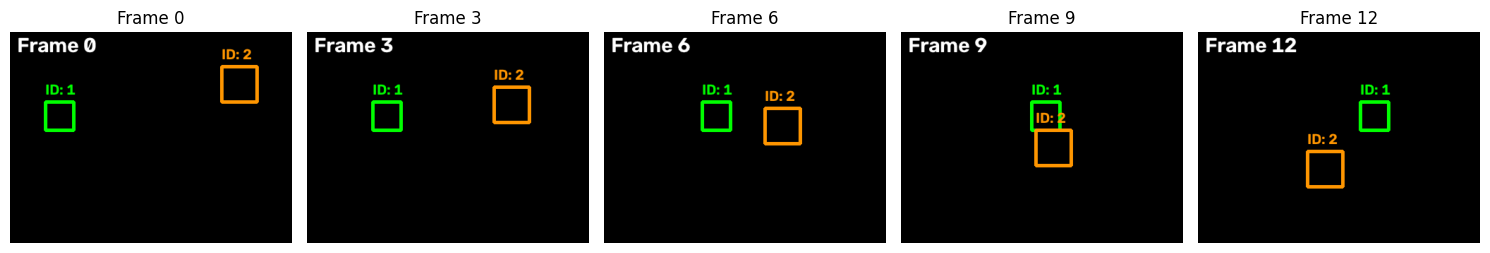

SUCCESS: Object IDs remain stable even after intersection!


In [5]:
class Track:
    def __init__(self, track_id, bbox):
        self.track_id = track_id
        self.age = 0
        self.hits = 1
        self.time_since_update = 0
        
        # Initialize Kalman
        self.kf = KalmanFilter(dim_x=7, dim_z=4)
        self.kf.F = np.eye(7)
        for i in range(3): self.kf.F[i, i+4] = 1 # State: [x,y,s,r, dx,dy,ds]
        self.kf.H = np.zeros((4, 7))
        for i in range(4): self.kf.H[i, i] = 1
        
        # Format: Center X, Center Y, Scale (Area), Ratio
        w, h = bbox[2]-bbox[0], bbox[3]-bbox[1]
        self.kf.x[:4] = np.array([[bbox[0]+w/2], [bbox[1]+h/2], [w*h], [w/h]])

    def predict(self):
        self.kf.predict()
        self.age += 1
        self.time_since_update += 1
        return self.get_state()

    def update(self, bbox):
        self.time_since_update = 0
        self.hits += 1
        w, h = bbox[2]-bbox[0], bbox[3]-bbox[1]
        self.kf.update(np.array([[bbox[0]+w/2], [bbox[1]+h/2], [w*h], [w/h]]))

    def get_state(self):
        x, y, s, r = self.kf.x[:4].flatten()
        w = np.sqrt(s * r)
        h = s / w
        return [x-w/2, y-h/2, x+w/2, y+h/2]

class SimpleSORT:
    def __init__(self, max_age=5, iou_thresh=0.3):
        self.tracks = []
        self.next_id = 1
        self.max_age = max_age
        self.iou_thresh = iou_thresh

    def update(self, detections):
        # 1. Predict all tracks
        predicted_boxes = [trk.predict() for trk in self.tracks]
        
        # 2. Hungarian Matching
        matched, unmatched_dets, unmatched_trks = [], list(range(len(detections))), list(range(len(self.tracks)))
        if len(self.tracks) > 0 and len(detections) > 0:
            iou_mat = np.zeros((len(self.tracks), len(detections)))
            for t, trk_box in enumerate(predicted_boxes):
                for d, det_box in enumerate(detections):
                    iou_mat[t, d] = calculate_iou(trk_box, det_box)
            
            row_ind, col_ind = linear_sum_assignment(-iou_mat) # Maximize IoU -> Minimize -IoU
            
            unmatched_dets, unmatched_trks = [], []
            for t, d in zip(row_ind, col_ind):
                if iou_mat[t, d] >= self.iou_thresh:
                    matched.append((t, d))
                else:
                    unmatched_trks.append(t)
                    unmatched_dets.append(d)
            # Add leftover tracks/dets
            unmatched_trks += list(set(range(len(self.tracks))) - set(row_ind))
            unmatched_dets += list(set(range(len(detections))) - set(col_ind))

        # 3. Update Matched Tracks
        for t, d in matched:
            self.tracks[t].update(detections[d])

        # 4. Create New Tracks
        for d in unmatched_dets:
            self.tracks.append(Track(self.next_id, detections[d]))
            self.next_id += 1

        # 5. Delete Dead Tracks
        self.tracks = [t for t in self.tracks if t.time_since_update <= self.max_age]
        
        return [(t.get_state(), t.track_id) for t in self.tracks if t.time_since_update == 0]

# --- SYNTHETIC VIDEO & PIPELINE TEST ---
tracker = SimpleSORT()
vis_frames = []

for frame_idx in range(15):
    # Create black background
    frame = np.zeros((300, 400, 3), dtype=np.uint8)
    detections = []
    
    # Object 1 (Moves Right)
    x1, y1 = 50 + frame_idx * 15, 100
    detections.append([x1, y1, x1+40, y1+40])
    
    # Object 2 (Moves Down-Left, Crossing Object 1 at frame 7!)
    x2, y2 = 300 - frame_idx * 12, 50 + frame_idx * 10
    detections.append([x2, y2, x2+50, y2+50])
    
    # Update Tracker
    active_tracks = tracker.update(detections)
    
    # Visualization
    for bbox, t_id in active_tracks:
        x, y, xmax, ymax = map(int, bbox)
        color = (0, 255, 0) if t_id == 1 else (0, 150, 255)
        cv2.rectangle(frame, (x, y), (xmax, ymax), color, 3)
        cv2.putText(frame, f"ID: {t_id}", (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
        
    cv2.putText(frame, f"Frame {frame_idx}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (255,255,255), 2)
    if frame_idx % 3 == 0: vis_frames.append(frame)

show_frames(vis_frames, [f"Frame {i*3}" for i in range(len(vis_frames))], cols=5)
print("SUCCESS: Object IDs remain stable even after intersection!")

## Day 22 & 23 — Tracking Evaluation & ByteTrack
**Topics:** MOTChallenge, Multi-Object Tracking Evaluation, ByteTrack Analysis

### 1. Tracking Failure Analysis
When your tracker fails, you must identify which layer of the pipeline broke:
1. **Detection Failure:** YOLO entirely misses a person in shadow. (Fix: Better training data or lower conf threshold).
2. **Association Failure (ID Switch):** Two people cross, and the Hungarian matrix matches them to the wrong tracks because they look physically identical and occupy the same space. (Fix: DeepSORT - Add ReID / Cosine Similarity embedding).
3. **Prediction Failure:** A car turns a sharp 90-degree corner rapidly. The Linear Kalman Filter predicts it went straight, moving the predicted box away from the YOLO box, causing a missed match. (Fix: Extended Kalman Filter).
4. **Lifecycle Failure (Fragmentation):** A person goes behind a wall for 60 frames. The tracker `max_age` is 30. The track dies. When the person emerges, they get a *new* ID.

### 2. ByteTrack Revolution (The Two-Pass Match)
Standard SORT deletes YOLO detections if their confidence is below 0.5. 
* **The Problem:** If an object is partially occluded, YOLO's confidence drops to 0.3. SORT deletes it, and the track is starved of updates.
* **ByteTrack's Solution:** It keeps *all* detections. 
  * **Pass 1:** Match High-Confidence detections (>0.5) to existing tracks using IoU.
  * **Pass 2:** Take the *remaining unmatched tracks* (which are probably occluded) and try to match them with the Low-Confidence detections (0.1 to 0.5). 
  * This simple logic revolutionized tracking, allowing recovery of heavily occluded objects without heavy neural networks!

In [6]:
video_path = "data/videos/people-detection.mp4"

print("--- STARTING REAL VIDEO TRACKING (CUSTOM SORT) ---")
cap = cv2.VideoCapture(video_path)
w, h, fps = (int(cap.get(x)) for x in (cv2.CAP_PROP_FRAME_WIDTH, cv2.CAP_PROP_FRAME_HEIGHT, cv2.CAP_PROP_FPS))
out_path = 'data/videos/sort_output.mp4'
out = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

yolo_model = YOLO('yolov8n.pt')
tracker_real = SimpleSORT(max_age=15, iou_thresh=0.3)

frame_count = 0
while cap.isOpened() and frame_count < 90: # Process only the first 3 seconds to save time
    ret, frame = cap.read()
    if not ret: break
    
    # 1. YOLO Detection (Filter only class 0: person)
    results = yolo_model(frame, classes=[0], verbose=False)[0]
    
    # Extract bounding boxes for high-confidence detections
    detections = [box.xyxy[0].cpu().numpy() for box in results.boxes if box.conf[0] > 0.4]
    
    # 2. Tracking Update
    active_tracks = tracker_real.update(detections)
    
    # 3. Visualization
    for bbox, t_id in active_tracks:
        x1, y1, x2, y2 = map(int, bbox)
        cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 0, 150), 2)
        cv2.putText(frame, f"ID: {t_id}", (x1, max(20, y1-10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
        
    out.write(frame)
    frame_count += 1

cap.release()
out.release()
print(f"SUCCESS: Custom SORT tracking video saved to '{out_path}'")

--- STARTING REAL VIDEO TRACKING (CUSTOM SORT) ---
SUCCESS: Custom SORT tracking video saved to 'data/videos/sort_output.mp4'


In [7]:
print("--- STARTING BYTETRACK PIPELINE ---")
# Run Ultralytics Native ByteTrack on the same video
track_results = yolo_model.track(
    source=video_path,
    classes=[0],               # Track people only
    tracker="bytetrack.yaml",  # The magic parameter!
    conf=0.25,                 # Lower confidence allowed because ByteTrack handles low-conf boxes in pass 2
    save=True,                 # Automatically save the output video
    project="data/videos",
    name="bytetrack_output",
    exist_ok=True,
    verbose=False
)

print("SUCCESS: ByteTrack processing complete! Check the 'data/videos/bytetrack_output' folder.")

# --- FAILURE ANALYSIS WORKSHOP ---
print("\\n--- TRACKING FAILURE ANALYSIS CHECKLIST ---")
print("When evaluating on MOTChallenge, if your tracker fails, ask these 4 questions:")
print("1. Did ID 5 change to ID 8 after crossing behind a sign? -> ASSOCIATION FAILURE (Fix: Add DeepSORT ReID/Cosine Similarity).")
print("2. Did the bounding box jump off the person during a fast sprint? -> PREDICTION FAILURE (Fix: Tune Kalman Filter Q matrix).")
print("3. Did the box completely disappear in the shadow? -> DETECTION FAILURE (Fix: Lower YOLO conf threshold or retrain model).")
print("4. Did a person get a new ID after standing still behind a truck for 3 minutes? -> LIFECYCLE FAILURE (Fix: Increase tracker max_age).")

--- STARTING BYTETRACK PIPELINE ---
WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /home/norbert/Projects/computer_vision_oly/object_tracking/runs/detect/data/videos/bytetrack_output
SUCCESS: ByteTrack processing complete! Check the 'data/videos/bytetrack_output' folder.
\n--- TRACKING FAILURE ANALYSIS CHECKLIST ---
When evaluating on MOTChallenge, if your tracker fails, ask these 4 questions:
1. Did ID 5 change to ID 8 after crossing behind a sign? -> ASSOCIATION FAILURE (Fix: Add De